In [16]:
from pesummary.io import read;

from pycbc.inference.io import loadfile;
from pycbc import conversions as cvs;
from pycbc import cosmology as cos;

import numpy as np
import matplotlib.pyplot as pp
# %matplotlib notebook
import seaborn as sns

import pandas as pd

pp.rcParams.update({
    "text.usetex": False,  # 启用 LaTeX 渲染
    # "font.family": "serif",  # 可选：设置字体为衬线字体（与 LaTeX 风格一致）
    # "font.serif": ["Times New Roman", "Computer Modern Roman"],  # 可选：指定字体
});
pp.rcParams.update(pp.rcParamsDefault);

In [17]:
def augment_OGC_XAS_result(samples, approximant='SEOBNRv4PHM', f_ref=20) :
    # lalsuite里面只有SEOBNR的几个模型能算m_f, a_f
    samples = samples.add_fields(cvs.mass1_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass1')
    samples = samples.add_fields(cvs.mass2_from_mchirp_q(samples['srcmchirp'], samples['q']), 'mass2')
    samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')

    samples = samples.add_fields(cvs.mtotal_from_mass1_mass2(samples['mass1'], samples['mass2']), 'Mtot')
    samples = samples.add_fields(samples['srcmchirp'], 'Mchirp')
    # samples = samples.add_fields(cvs.eta_from_mass1_mass2(samples['mass1'], samples['mass2']), 'eta')
    samples = samples.add_fields(cvs.invq_from_mass1_mass2(samples['mass1'], samples['mass2']), 'invq')

    # samples = samples.add_fields(cvs.chi_eff_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_polar'], samples['spin2_a'], samples['spin2_polar']), 'chi_eff')
    # samples = samples.add_fields(cvs.chi_p_from_spherical(samples['mass1'], samples['mass2'], samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'], samples['spin2_a'],samples['spin1_azimuthal'], samples['spin2_polar']), 'chi_p')

    samples = samples.add_fields(cos.distance_from_comoving_volume(samples['comoving_volume']), 'distance')
    samples = samples.add_fields(cos.redshift_from_comoving_volume(samples['comoving_volume']), 'redshift')
    
    def chi_hat_PN(m1,m2,chi1,chi2) :
        eta = cvs.eta_from_mass1_mass2(m1,m2)
        N = 1 - 76/133*eta
        chi_eff = cvs.chi_eff(m1,m2,chi1,chi2)
        term = -38/113*eta*(chi1+chi2)
        chi_PN = chi_eff + term
        return chi_PN / N
        # cvs.chi_eff(samples['mass1'], samples['mass2'],samples['spin1z'],samples['spin2z'])
    samples = samples.add_fields(chi_hat_PN(samples['mass1'], samples['mass2'],samples['spin1z'],samples['spin2z']), 'chi_hat_PN')
    
    temp = {}
    # temp['spin1_x'], temp['spin1_y'], temp['spin1_z'] = cvs._spherical_to_cartesian(samples['spin1_a'], samples['spin1_azimuthal'], samples['spin1_polar'])
    # temp['spin2_x'], temp['spin2_y'], temp['spin2_z'] = cvs._spherical_to_cartesian(samples['spin2_a'], samples['spin2_azimuthal'], samples['spin2_polar'])

    # samples = samples.add_fields(temp['spin1_x'], 'spin1_x')
    # samples = samples.add_fields(temp['spin1_y'], 'spin1_y')
    # samples = samples.add_fields(samples['spin1z'], 'spin1z')
    # samples = samples.add_fields(temp['spin2_x'], 'spin2_x')
    # samples = samples.add_fields(temp['spin2_y'], 'spin2_y')
    # samples = samples.add_fields(samples['spin2z'], 'spin2z')


    # 这两个算得很慢
    # samples = samples.add_fields(cvs.final_mass_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'm_f')
    # samples = samples.add_fields(cvs.final_spin_from_initial(samples['mass1'], samples['mass2'], samples['spin1_x'], samples['spin1_y'], samples['spin1_z'], samples['spin2_x'], samples['spin2_y'], samples['spin2_z'], approximant=approximant, f_ref=f_ref), 'a_f')

    return samples

In [18]:
posteriors_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GWTC-1_PGen"

samples = {}
samples['GW150914'] = {}
samples['GW150914'] = {}
samples['GW151012'] = {}
samples['GW151226'] = {}
samples['GW170104'] = {}
samples['GW170608'] = {}
samples['GW170729'] = {}
samples['GW170809'] = {}
samples['GW170818'] = {}
samples['GW170823'] = {}
samples['GW170814'] = {}

event_id = "GW151226"

In [19]:
# IMRPhenomPv2 & SEOBNRv4_ROM
# AlphaNS
wffs = {"IMRP","SEOB"}
types = {"phi","alpha","beta"}

orders = {}
orders["phi"] = {"0","2","3","4","5l","6","6l","7"}
orders["alpha"] = {"2","3","4"}
orders["beta"] = {"2","3"}

deviations = {}
for wff in wffs:
    deviations[wff] = []
    for t in types:
        for o in orders[t]:
            deviations[wff].append(f"d{t}_{o}_{wff}_posterior")

devs = deviations["IMRP"] + deviations["SEOB"]

In [20]:
import h5py
import pandas as pd

# 假设posteriors_path和event_id已定义
file_path = f"{posteriors_path}/{event_id}_GWTC-1-TGR.hdf5"
data_dict = {}  # 存储所有数据集的字典

with h5py.File(file_path, 'r') as fp:
    # 遍历文件中的所有顶级数据集（dataset）
    for key in fp.keys():
        # 读取数据集的完整数据（[:] 表示加载所有数据）
        data_dict[key] = pd.DataFrame(fp[key][:])


In [21]:
from pycbc.waveform import fd_approximants, td_approximants

print("=== 频域波形 ===")
for name in sorted(fd_approximants()):
    print(name)

# print("\n=== 时域波形 ===")
# for name in sorted(td_approximants()):
#     print(name)



=== 频域波形 ===
EOBNRv2HM_ROM
EOBNRv2HM_ROM_INTERP
EOBNRv2_ROM
EOBNRv2_ROM_INTERP
EccentricFD
ExternalPython
IMRPhenomA
IMRPhenomB
IMRPhenomC
IMRPhenomC_INTERP
IMRPhenomD
IMRPhenomD_INTERP
IMRPhenomD_NRTidal
IMRPhenomD_NRTidal_INTERP
IMRPhenomD_NRTidalv2
IMRPhenomHM
IMRPhenomHM_INTERP
IMRPhenomNSBH
IMRPhenomP
IMRPhenomPv2
IMRPhenomPv2_INTERP
IMRPhenomPv2_NRTidal
IMRPhenomPv2_NRTidal_INTERP
IMRPhenomPv2_NRTidalv2
IMRPhenomPv3
IMRPhenomPv3HM
IMRPhenomPv3HM_INTERP
IMRPhenomXAS
IMRPhenomXAS_NRTidalv2
IMRPhenomXAS_NRTidalv3
IMRPhenomXHM
IMRPhenomXHM_INTERP
IMRPhenomXO4a
IMRPhenomXP
IMRPhenomXPHM
IMRPhenomXPHM_INTERP
IMRPhenomXP_NRTidalv2
IMRPhenomXP_NRTidalv3
Lackey_Tidal_2013_SEOBNRv2_ROM
NRSur4d2s
PreTaylorF2
PreTaylorF2_INTERP
SEOBNRv1_ROM_DoubleSpin
SEOBNRv1_ROM_DoubleSpin_INTERP
SEOBNRv1_ROM_EffectiveSpin
SEOBNRv1_ROM_EffectiveSpin_INTERP
SEOBNRv2_ROM_DoubleSpin
SEOBNRv2_ROM_DoubleSpin_HI
SEOBNRv2_ROM_DoubleSpin_HI_INTERP
SEOBNRv2_ROM_DoubleSpin_INTERP
SEOBNRv2_ROM_EffectiveSpin
SEOBNRv2_

In [22]:
# import os
# import pandas as pd

# csv_path = f"/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/{event_id}"
# os.makedirs(csv_path, exist_ok=True)

# # 列名映射：原始名 -> CSV里显示的名字
# rename_map = {
#     'm1_detector_frame_Msun': 'm1',
#     'm2_detector_frame_Msun': 'm2',
#     'spin1': 'spin1z',
#     'spin2': 'spin2z',
# }

# for dataset in data_dict.keys():
#     df = data_dict[dataset].copy()
    
#     # 提取偏差参数名（如 'dalpha_2_IMRP_posterior' -> 'dalpha_2'）
#     param_name = '_'.join(dataset.split('_')[:-2])
    
#     # 重命名
#     df = df.rename(columns=rename_map)
#     # 偏差参数列名也统一改成短名（如果原始列名带后缀的话）
#     # 如果列名里直接就是 param_name 就不用改
    
#     # 前五列（重命名后的名字）
#     primary_cols = ['m1', 'm2', 'spin1z', 'spin2z', param_name]
    
#     # 过滤出实际存在的前五列
#     existing_primary = [col for col in primary_cols if col in df.columns]
    
#     # 其余列
#     other_cols = [col for col in df.columns if col not in existing_primary]
    
#     # 拼接：前五列在前，其余在后
#     final_cols = existing_primary + other_cols
    
#     csv_filepath = os.path.join(csv_path, f"{dataset}.csv")
#     df[final_cols].to_csv(csv_filepath, index=False)
#     print(f"CSV 已保存: {csv_filepath}")


In [23]:
import os
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u

# ================= 1. 预先构建 光度距离 -> 红移 的快速插值器 =================
z_grid = np.linspace(0, 2, 5000)
dl_grid = cosmo.luminosity_distance(z_grid).value 

z_from_dl_interp = interp1d(dl_grid, z_grid, kind='cubic', bounds_error=False, fill_value=(0, z_grid[-1]))
# =========================================================================

csv_path = f"/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/{event_id}"
os.makedirs(csv_path, exist_ok=True)

rename_map = {
    'm1_source_frame_Msun': 'm1',
    'm2_source_frame_Msun': 'm2',
    'spin1': 'spin1z',
    'spin2': 'spin2z',
}

for dataset in data_dict.keys():
    df = data_dict[dataset].copy()
    
    # 2. 使用插值函数批量、快速计算红移 z
    z = z_from_dl_interp(df['luminosity_distance_Mpc'].values)
    
    # 【新增】将计算出的红移保存为 DataFrame 的新列
    df['redshift'] = z
    
    # 3. 计算源帧质量：m_source = m_detector / (1 + z)
    df['m1_source_frame_Msun'] = df['m1_detector_frame_Msun'] / (1 + z)
    df['m2_source_frame_Msun'] = df['m2_detector_frame_Msun'] / (1 + z)
    
    # 提取偏差参数名
    param_name = '_'.join(dataset.split('_')[:-2])
    
    # 重命名
    df = df.rename(columns=rename_map)
    
    # 【修改】前五列改为前六列，把 redshift 加在 m2 后面
    primary_cols = ['m1', 'm2', 'spin1z', 'spin2z', param_name]
    
    # 过滤出实际存在的前几列
    existing_primary = [col for col in primary_cols if col in df.columns]
    
    # 其余列
    other_cols = [col for col in df.columns if col not in existing_primary]
    
    # 拼接
    final_cols = existing_primary + other_cols
    
    csv_filepath = os.path.join(csv_path, f"{dataset}.csv")
    df[final_cols].to_csv(csv_filepath, index=False)
    print(f"CSV 已保存: {csv_filepath}")


CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW151226/dphi_-2_IMRP_posterior.csv
CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW151226/dphi_-2_SEOB_posterior.csv
CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW151226/dphi_0_IMRP_posterior.csv
CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW151226/dphi_0_SEOB_posterior.csv
CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW151226/dphi_1_IMRP_posterior.csv
CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW151226/dphi_1_SEOB_posterior.csv
CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW151226/dphi_2_IMRP_posterior.csv
CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW151226/dphi_2_SEOB_posterior.csv
CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Paramet

In [24]:
import h5py
import pandas as pd

# 假设posteriors_path和event_id已定义
file_path = f"/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GWTC-1_sample_release/{event_id}_GWTC-1.hdf5"
data_dict_GR = {}  # 存储所有数据集的字典

with h5py.File(file_path, 'r') as fp:
    # 遍历文件中的所有顶级数据集（dataset）
    for key in fp.keys():
        # 读取数据集的完整数据（[:] 表示加载所有数据）
        data_dict_GR[key] = pd.DataFrame(fp[key][:])

In [25]:
import os
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u

# ================= 1. 预先构建 光度距离 -> 红移 的快速插值器 =================
z_grid = np.linspace(0, 2, 5000)
dl_grid = cosmo.luminosity_distance(z_grid).value 

z_from_dl_interp = interp1d(dl_grid, z_grid, kind='cubic', bounds_error=False, fill_value=(0, z_grid[-1]))
# =========================================================================

csv_path = f"/mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/{event_id}"
os.makedirs(csv_path, exist_ok=True)

rename_map = {
    'm1_source_frame_Msun': 'm1',
    'm2_source_frame_Msun': 'm2',
    'spin1': 'spin1z',
    'spin2': 'spin2z',
}


df = data_dict_GR["IMRPhenomPv2_posterior"].copy()

# 2. 使用插值函数批量、快速计算红移 z
z = z_from_dl_interp(df['luminosity_distance_Mpc'].values)

# 【新增】将计算出的红移保存为 DataFrame 的新列
df['redshift'] = z

# 3. 计算源帧质量：m_source = m_detector / (1 + z)
df['m1_source_frame_Msun'] = df['m1_detector_frame_Msun'] / (1 + z)
df['m2_source_frame_Msun'] = df['m2_detector_frame_Msun'] / (1 + z)

# 提取偏差参数名

# 重命名
df = df.rename(columns=rename_map)

# 【修改】前五列改为前六列，把 redshift 加在 m2 后面
primary_cols = ['m1', 'm2', 'spin1z', 'spin2z']

# 过滤出实际存在的前几列
existing_primary = [col for col in primary_cols if col in df.columns]

# 其余列
other_cols = [col for col in df.columns if col not in existing_primary]

# 拼接
final_cols = existing_primary + other_cols

csv_filepath = os.path.join(csv_path, f"GR_IMRP_posterior.csv")
df[final_cols].to_csv(csv_filepath, index=False)
print(f"CSV 已保存: {csv_filepath}")


CSV 已保存: /mnt/d/Documents/workspace/课题/workspace/Local/Parameterized_PN_Tests/csv/GW151226/GR_IMRP_posterior.csv


In [26]:
pp.hist(df["redshift"],bins=100);

In [27]:
np.median(df["redshift"]),np.median(df["redshift"]) - np.quantile(df["redshift"],[0.05,0.95])

(0.09282028003149526, array([ 0.03926743, -0.03624671]))

# Visualisation

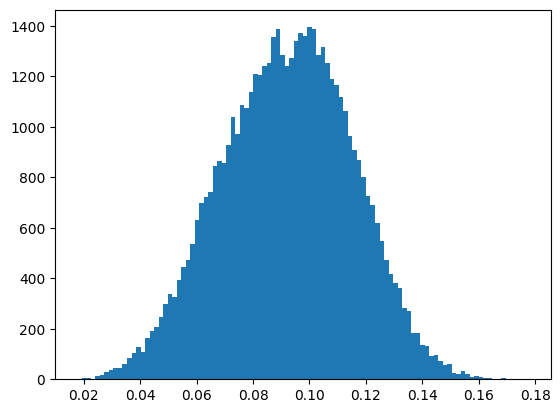

In [28]:
import pandas as pd
import corner
import numpy as np
import matplotlib.pyplot as plt
import os

# 参数映射（完整版，包含alpha和beta）
parameter_mapping = {
    'costheta_jn': r"$\cos\theta_{JN}$",
    'luminosity_distance_Mpc': r"$D_L$ (Mpc)",
    'right_ascension': r"$\alpha$",
    'declination': r"$\delta$",
    'm1_detector_frame_Msun': r"$m_1$",
    'm2_detector_frame_Msun': r"$m_2$",
    'spin1': r"$\chi_{1L}$",
    'spin2': r"$\chi_{2L}$",
    'costilt1': r"$\cos\iota_1$",
    'costilt2': r"$\cos\iota_2$",
    'dalpha_2': r"$\Delta\alpha_2$",
    'dalpha_3': r"$\Delta\alpha_3$",
    'dalpha_4': r"$\Delta\alpha_4$",
    'dbeta_2': r"$\Delta\beta_2$",
    'dbeta_3': r"$\Delta\beta_3$",
    'dphi_-2': r"$\Delta\phi_{-2}$",
    'dphi_0': r"$\Delta\phi_0$",
    'dphi_1': r"$\Delta\phi_1$",
    'dphi_2': r"$\Delta\phi_2$",
    'dphi_3': r"$\Delta\phi_3$",
    'dphi_4': r"$\Delta\phi_4$",
    'dphi_5l': r"$\Delta\phi_{5l}$",
    'dphi_6': r"$\Delta\phi_6$",
    'dphi_6l': r"$\Delta\phi_{6l}$",
    'dphi_7': r"$\Delta\phi_7$"
}

# 绘图设置
quantiles = [0.05, 0.50, 0.95]
fig_path = "/mnt/d/Documents/workspace/课题/论文/figs/GWTC-1"
plt.rcParams.update({'font.size': 12})

# 创建文件夹（如果不存在）
output_dir = os.path.join(fig_path, f"{event_id}/posteriors")
os.makedirs(output_dir, exist_ok=True)

# 处理每个数据集
datasets = list(data_dict.keys())
for dataset in datasets:
    # 提取参数名称（如从 'dalpha_2_IMRP_posterior' 提取 'dalpha_2'）
    param_name = dataset.split('_')[-2]
    
    # 构建列列表（仅保留存在的列）
    par_list1 = [col for col in ['m1_detector_frame_Msun', 'm2_detector_frame_Msun', 'spin1', 'spin2', 'chi_hat_PN', param_name] if col in data_dict[dataset].columns]
    
    # 第一个 corner 图：质量、自旋和目标参数
    corner.corner(data_dict[dataset][par_list1],
                quantiles=quantiles,
                show_titles=True,
                hist_kwargs={"density": True},
                labels=[r"$m_1$", r"$m_2$", r"$\chi_{1L}$", r"$\chi_{2L}$", r"$\hat{\chi}_\text{PN}$", parameter_mapping.get(param_name, f"$\\psi_{{{param_name.split('_')[-1]}}}$")])
    plt.savefig(f"{fig_path}/{event_id}/posteriors/{event_id}_posterior_{dataset}_0.pdf")
    plt.close()
    
    # 第二个 corner 图：角度和距离参数
    par_list2 = [col for col in ['costheta_jn', 'luminosity_distance_Mpc', 'redshift', 'right_ascension', 'declination', 'coa_phase', 'delta_tc'] if col in data_dict[dataset].columns]
    corner.corner(data_dict[dataset][par_list2],
                quantiles=quantiles,
                show_titles=True,
                hist_kwargs={"density": True},
                labels=[r"$\cos\theta_{JN}$", r"$D_L$", r"$z$", r"$\alpha$", r"$\delta$", r"$\phi_\text{c}$", r"$\Delta t_\text{c}$"])
    plt.savefig(f"{fig_path}/{event_id}/posteriors/{event_id}_posterior_{dataset}_1.pdf")
    plt.close()

plt.show()


In [29]:
import pickle

# 替换成你的 pkl 文件绝对路径/相对路径
pkl_path = "/mnt/d/Documents/workspace/课题/workspace/Local/Public/posteriors/ligo/GWTC-1_PGen/PGen_stats.pkl"

# 读取 pkl 文件（rb = 二进制只读模式，必须加）
with open(pkl_path, "rb") as f:
    data = pickle.load(f)

# 打印读取到的数据（查看内容）
print("读取成功！数据类型：", type(data))
print("数据内容：", data)

读取成功！数据类型： <class 'dict'>
数据内容： {'GW151012': {'dphi_6l': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')}, 'dalpha_3': {'IMRP': ('5', '-33', '+81', '29'), 'SEOB': ('-', '', '', '-')}, 'dphi_5l': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')}, 'dphi_6': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')}, 'dphi_7': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')}, 'dphi_4': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')}, 'dalpha_2': {'IMRP': ('0', '-3', '+14', '37'), 'SEOB': ('-', '', '', '-')}, 'dphi_2': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')}, 'dphi_3': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')}, 'dphi_0': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')}, 'dphi_1': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')}, 'dalpha_4': {'IMRP': ('6', '-30', '+24', '33'), 'SEOB': ('-', '', '', '-')}, 'dbeta_2': {'IMRP': ('0.3', '-0.6', '+3.8', '24'), 'SEOB': ('-', '', '', '-')}, 'dbeta_3': {'IMRP': ('3.3', '-

In [30]:
data['GW151012']

{'dphi_6l': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dalpha_3': {'IMRP': ('5', '-33', '+81', '29'), 'SEOB': ('-', '', '', '-')},
 'dphi_5l': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_6': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_7': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_4': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dalpha_2': {'IMRP': ('0', '-3', '+14', '37'), 'SEOB': ('-', '', '', '-')},
 'dphi_2': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_3': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_0': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_1': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dalpha_4': {'IMRP': ('6', '-30', '+24', '33'), 'SEOB': ('-', '', '', '-')},
 'dbeta_2': {'IMRP': ('0.3', '-0.6', '+3.8', '24'),
  'SEOB': ('-', '', '', '-')},
 'dbeta_3': {'IMRP': ('3.3', '-3.4', '+3.6', '5.6'),
  'SEOB'

In [31]:
data['GW151012']

{'dphi_6l': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dalpha_3': {'IMRP': ('5', '-33', '+81', '29'), 'SEOB': ('-', '', '', '-')},
 'dphi_5l': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_6': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_7': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_4': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dalpha_2': {'IMRP': ('0', '-3', '+14', '37'), 'SEOB': ('-', '', '', '-')},
 'dphi_2': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_3': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_0': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dphi_1': {'IMRP': ('-', '', '', '-'), 'SEOB': ('-', '', '', '-')},
 'dalpha_4': {'IMRP': ('6', '-30', '+24', '33'), 'SEOB': ('-', '', '', '-')},
 'dbeta_2': {'IMRP': ('0.3', '-0.6', '+3.8', '24'),
  'SEOB': ('-', '', '', '-')},
 'dbeta_3': {'IMRP': ('3.3', '-3.4', '+3.6', '5.6'),
  'SEOB'